#### EDA

Our analysis is mostly based on RFM features exploration

In [1]:
import pandas as pd
data = pd.read_parquet('../data/cleaned/retail_online.parquet')

#### Some statistic after cleaning data

In [2]:
print("Number of rows:", data.shape[0], "rows.")
print("Number of Invoices:", data['InvoiceNo'].nunique(), "invoices.")
print("Number of Customers:", data['CustomerID'].nunique(), "customers.")
print("Number of StockCode:", data['StockCode'].nunique(), "codes.")
print("Number of Countries:", data['Country'].nunique(), "countries.")

Number of rows: 404876 rows.
Number of Invoices: 21785 invoices.
Number of Customers: 4362 customers.
Number of StockCode: 3676 codes.
Number of Countries: 37 countries.


In [3]:
data['Revenue'] = data['Quantity'] * data['UnitPrice']
data[['Quantity', 'UnitPrice', 'Revenue']].describe()

,Quantity,UnitPrice,Revenue
count,404876.000000,404876.000000,404876.000000
mean,12.072511,2.901366,20.467164
std,248.467980,4.430949,422.793171
min,-80995.000000,0.030000,-168469.600000
25%,2.000000,1.250000,4.200000
50%,5.000000,1.950000,10.900000
75%,12.000000,3.750000,19.500000
max,80995.000000,649.500000,168469.600000


#### `Country`

In [4]:
data['Country'].value_counts()

Country
United Kingdom          361235
Germany                   9095
France                    8168
EIRE                      7378
Spain                     2467
Netherlands               2326
Belgium                   1971
Switzerland               1843
Portugal                  1436
Australia                 1254
Norway                    1059
Italy                      783
Channel Islands            753
Finland                    653
Cyprus                     619
Sweden                     437
Austria                    387
Denmark                    375
Japan                      355
Poland                     336
USA                        291
Israel                     250
Unspecified                244
Singapore                  215
Iceland                    182
Canada                     150
Greece                     142
Malta                      123
United Arab Emirates        67
European Community          58
RSA                         57
Lebanon                     45


Almost the recored transactions in this dataset are from UK

In [5]:
country_summary = data.groupby('Country').agg(
    total_orders=('InvoiceNo', 'nunique'),
    total_quanity=('Quantity', 'sum'),
    total_revenue=('Revenue', 'sum'),
    avg_order_value=('Revenue', 'mean'),
    unique_customers=('CustomerID', 'nunique')
).sort_values('total_revenue', ascending=False)
country_summary

,total_orders,total_quanity,total_revenue,avg_order_value,unique_customers
Country,,,,,
United Kingdom,19581,3993290,6822902.82,18.887712,3942
Netherlands,96,199934,283479.54,121.874265,9
EIRE,311,135984,247015.91,33.480064,3
Germany,578,116341,200808.40,22.078988,95
France,438,109058,181472.33,22.217474,87
Australia,67,83345,136990.00,109.242424,9
Switzerland,65,29680,51859.40,28.138578,21
Spain,100,26607,51765.20,20.983056,30
Belgium,117,22880,36662.96,18.601197,25


In [6]:
data['is_uk'] = (data['Country'] == 'United Kingdom').astype('int8')

In [7]:
is_uk = data[data['is_uk'] == 1]
non_uk = data[data['is_uk'] == 0]

compare = pd.DataFrame({
    "UK": [
        is_uk['InvoiceNo'].nunique(),
        is_uk['Quantity'].sum(),
        is_uk['Revenue'].sum(),
        is_uk['CustomerID'].nunique(),
        is_uk.groupby('InvoiceNo')['Revenue'].sum().mean()
    ],
    'Non_UK': [
        non_uk['InvoiceNo'].nunique(),
        non_uk['Quantity'].sum(),
        non_uk['Revenue'].sum(),
        non_uk['CustomerID'].nunique(),
        non_uk.groupby('InvoiceNo')['Revenue'].sum().mean()
    ]
}, index=['orders', 'total_quantity', 'total_revenue', 'customers', 'avg_order_value'])

In [8]:
compare

,UK,Non_UK
orders,1.958100e+04,2.204000e+03
total_quantity,3.993290e+06,8.945800e+05
total_revenue,6.822903e+06,1.463760e+06
customers,3.942000e+03,4.200000e+02
avg_order_value,3.484451e+02,6.641382e+02


- The UK overwhelmingly dominates the dataset, accounting for 90.4% of customers, 89.9% orders, 82.3% of total revenue.
- Despite of making up only 9.6% of customers, international buyers contribute 17.7% of total revenue and 18.3% of total quantity.
- Non-UK customers exhibit an Average Order Value 664.14 euros 0 - almost 1.9x higher than UK customer, and also generate 2x higher revenue per customers.
- Decision: Collapse `Country` into a binary indicator feature `is_uk` to capture distinct spending scale between domestic and international segments.

#### RFM features explore

In [9]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
if root.name == "notebook":
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [10]:
from src.feature_engineering import extract_customer_features
df = extract_customer_features(df=data)

##### Visualization

(<Figure size 900x600 with 1 Axes>,
 <Axes: title={'center': 'Buyer Typology: Variety (Distinct Products) vs Volume (Items/Order)'}, xlabel='NumDistinctProducts (Log Scale)', ylabel='AvgItemsPerOrder (Log Scale)'>)

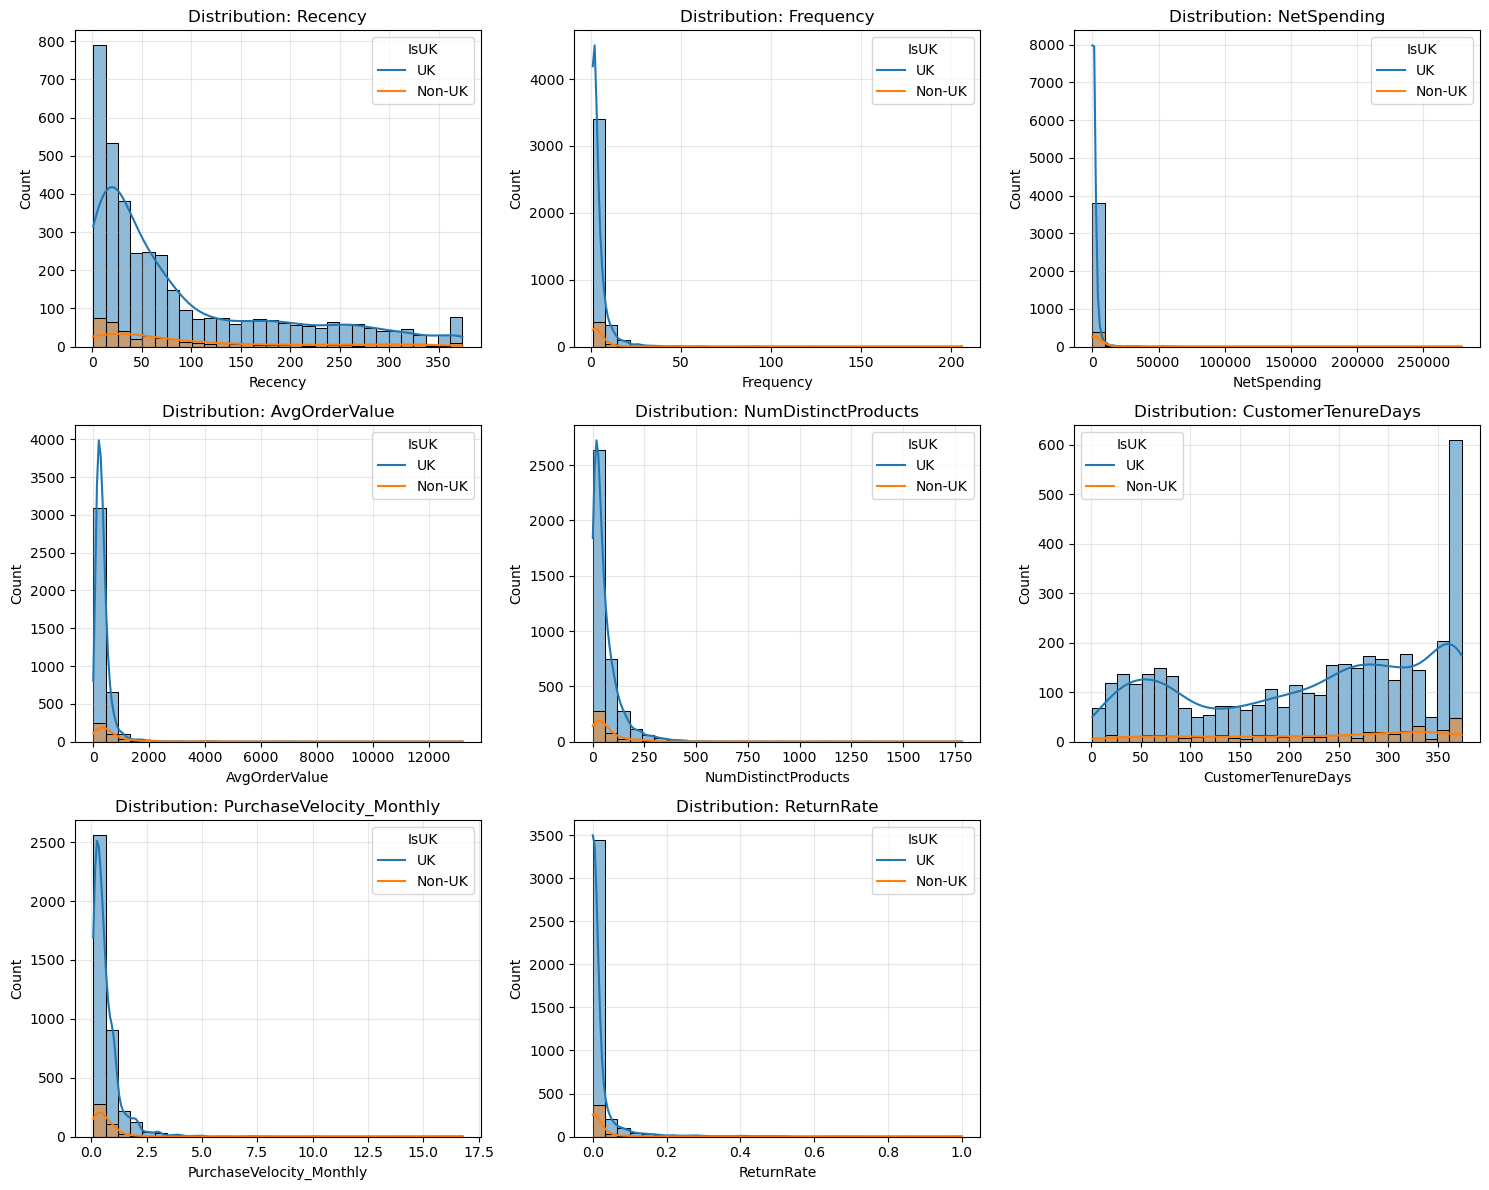

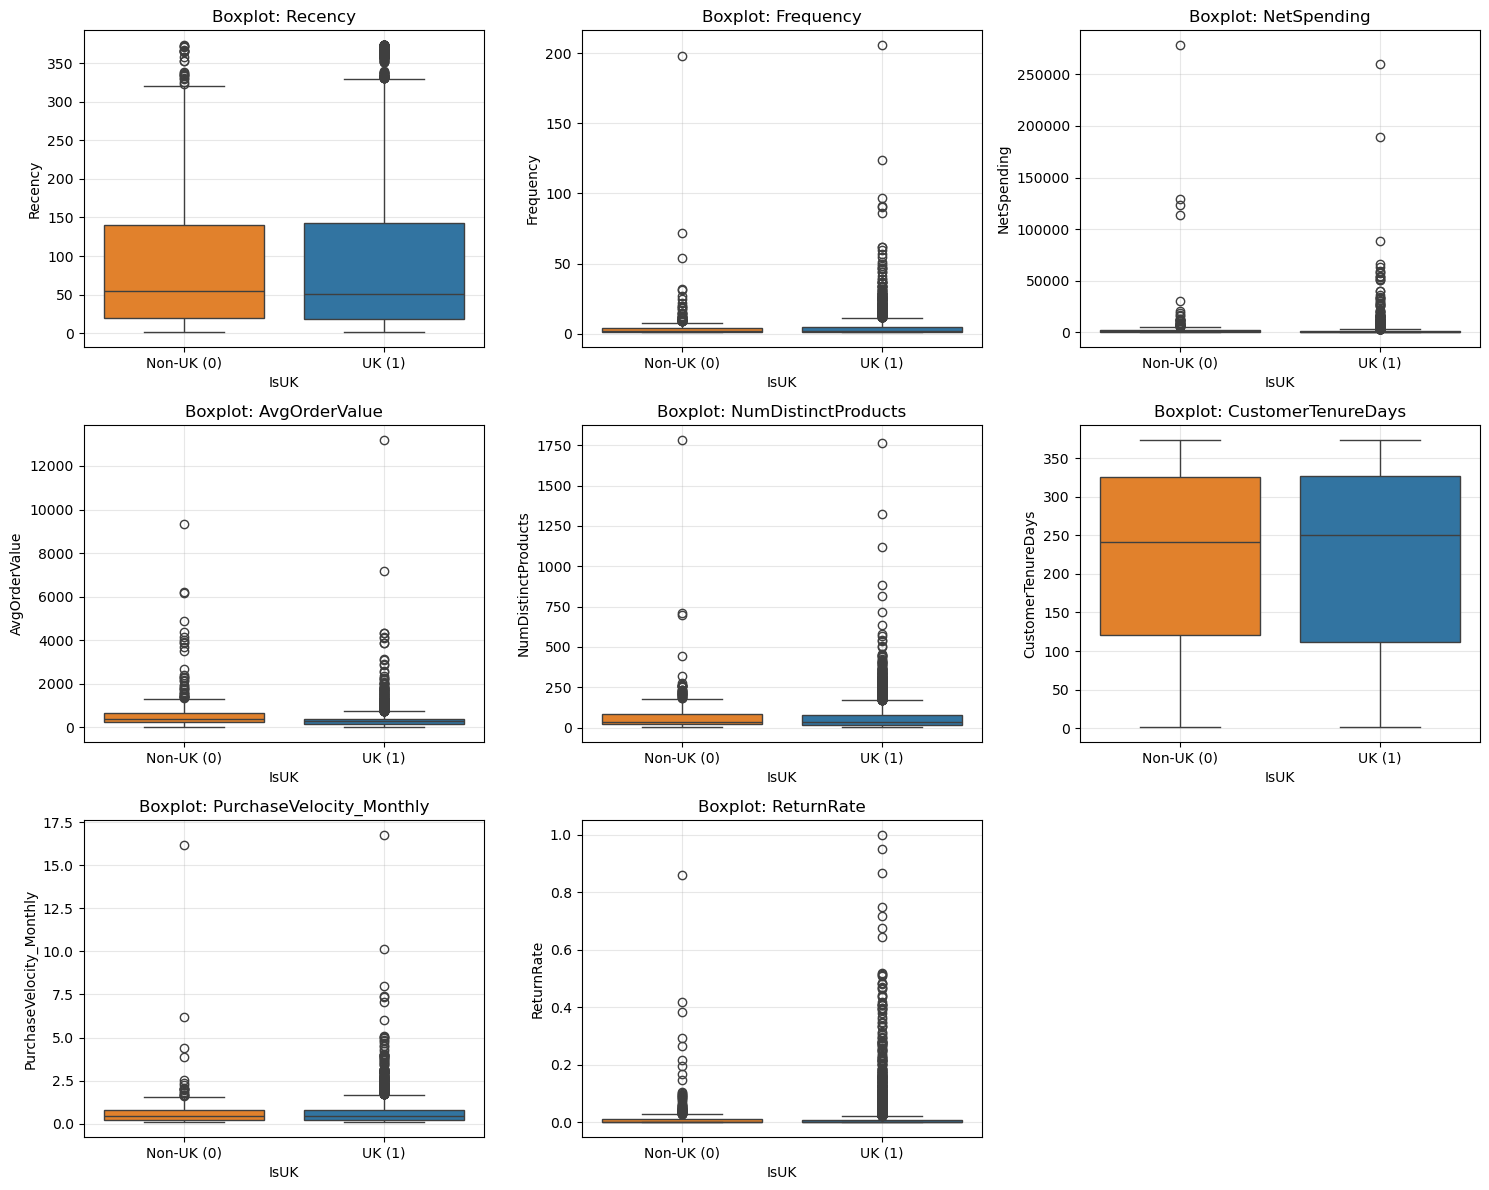

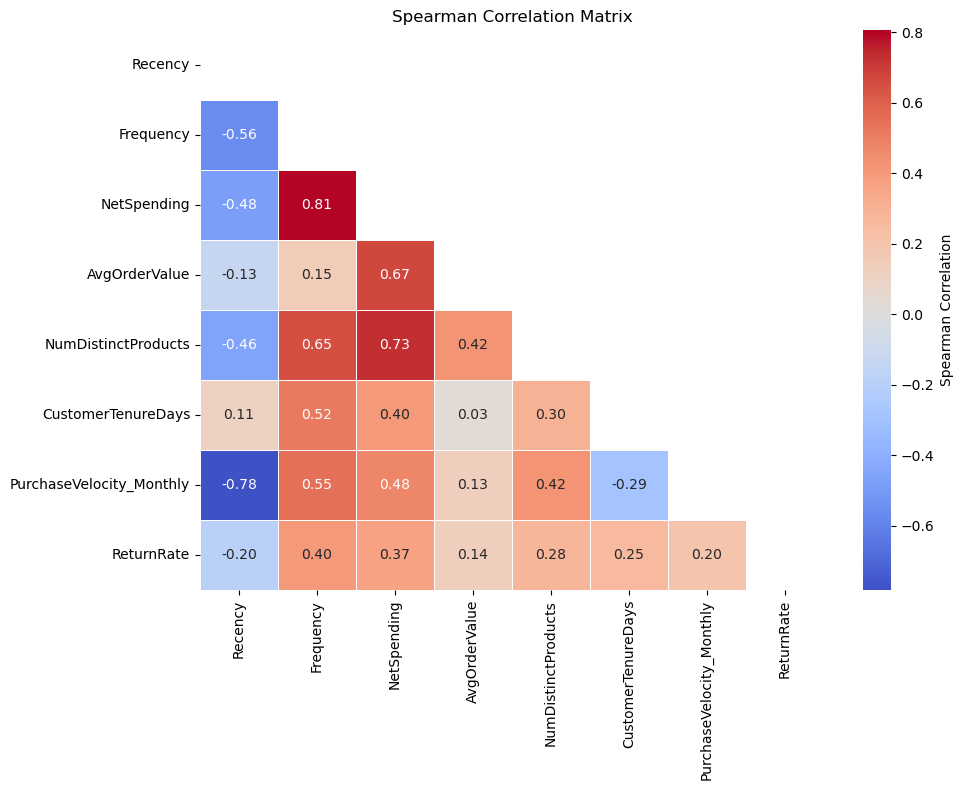

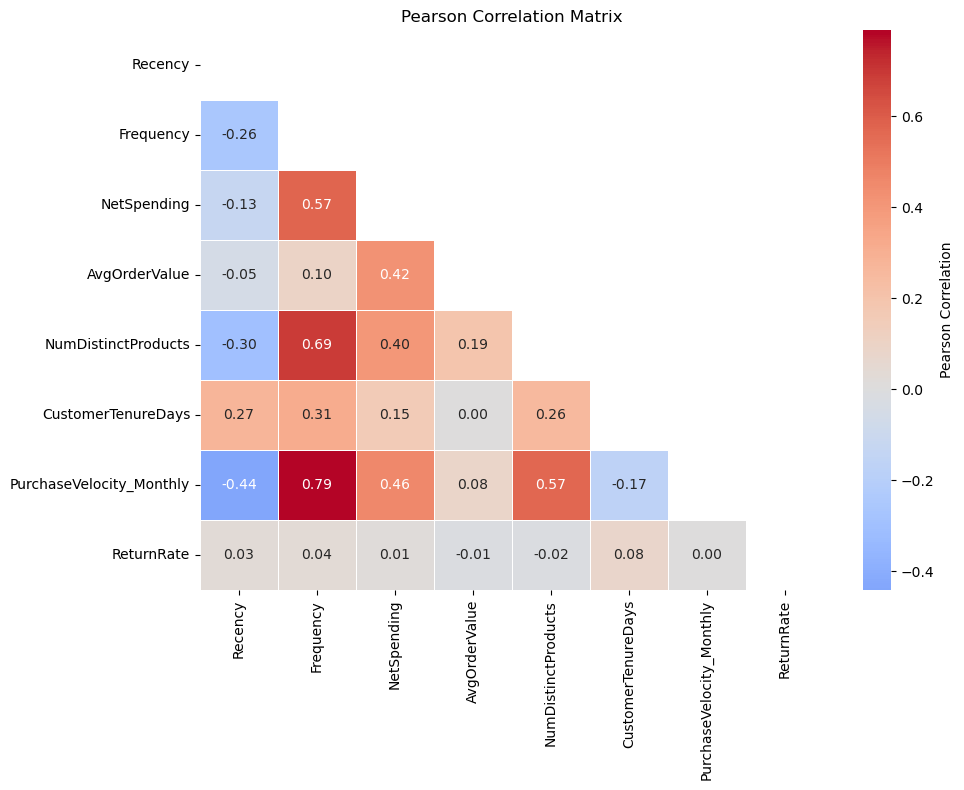

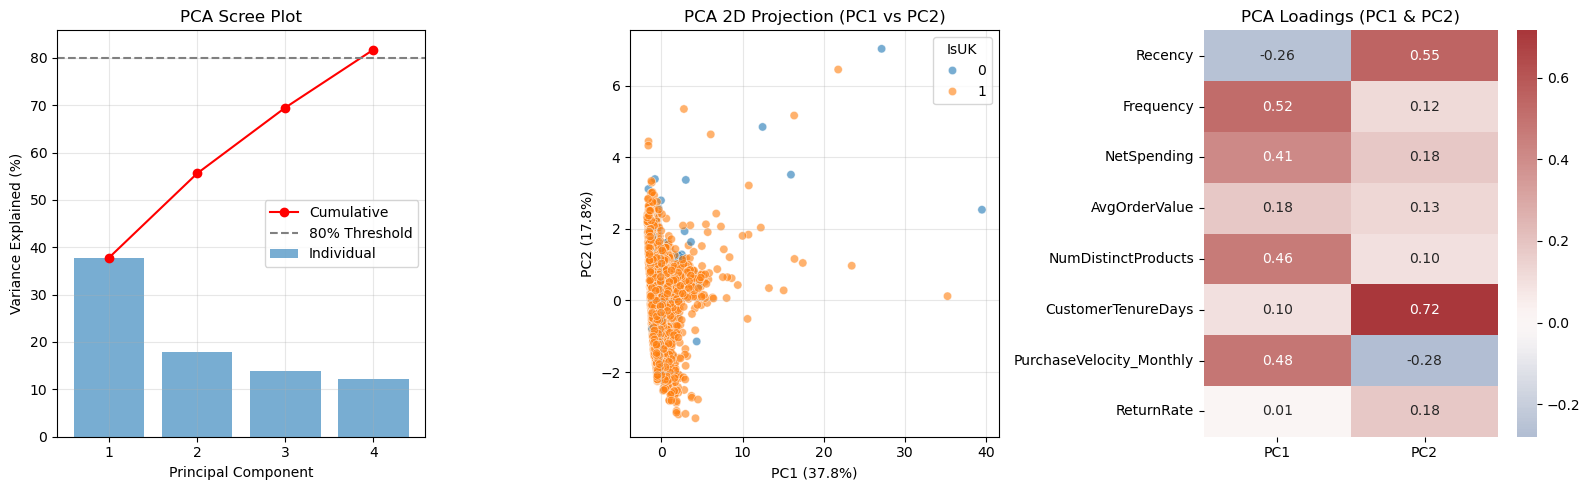

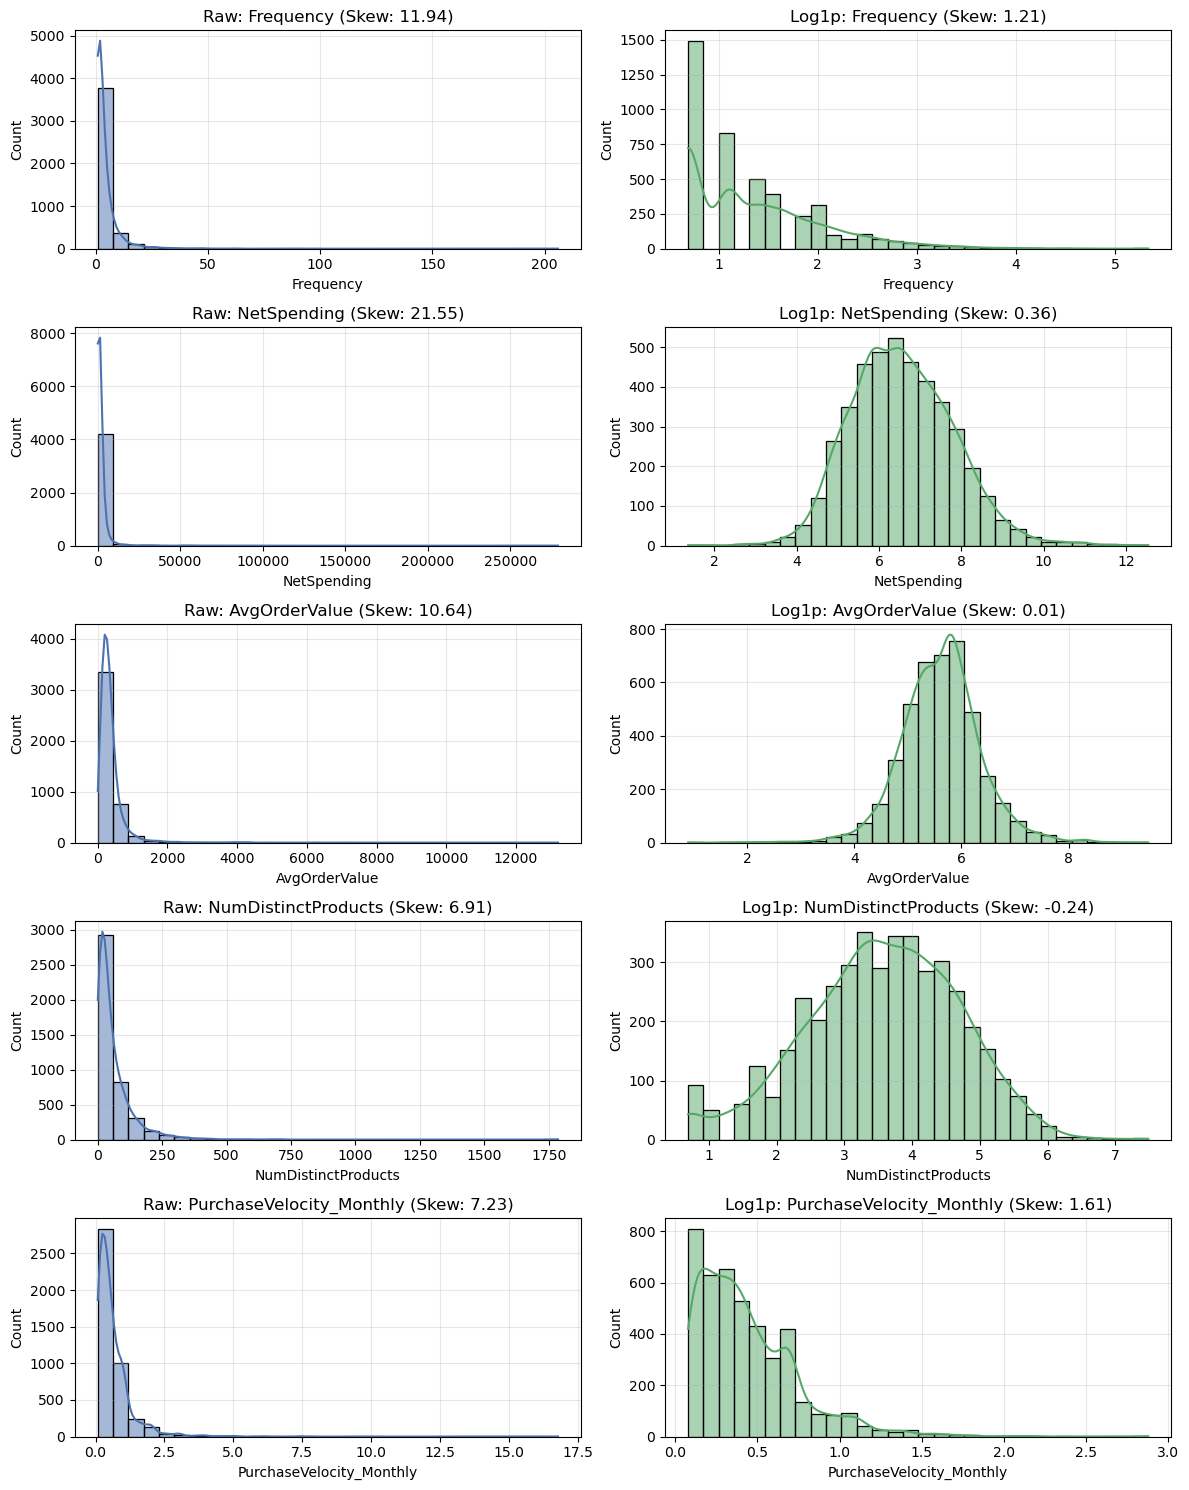

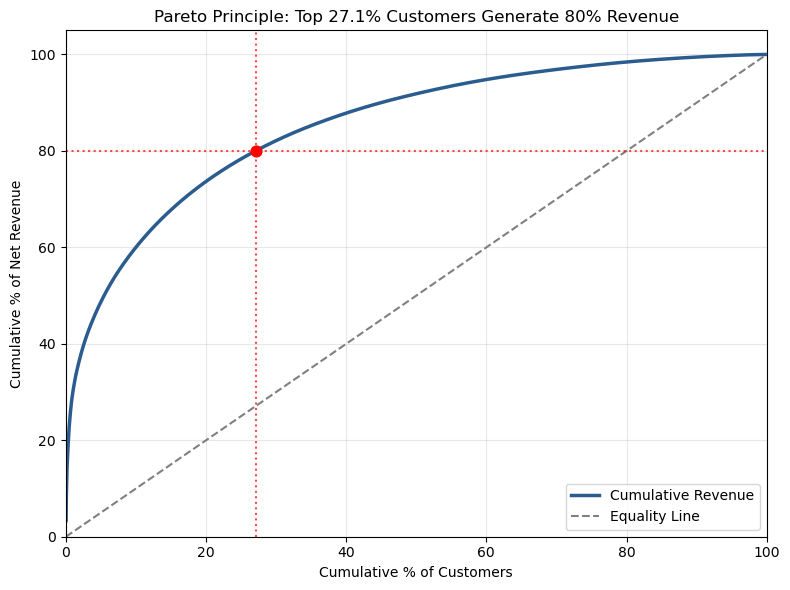

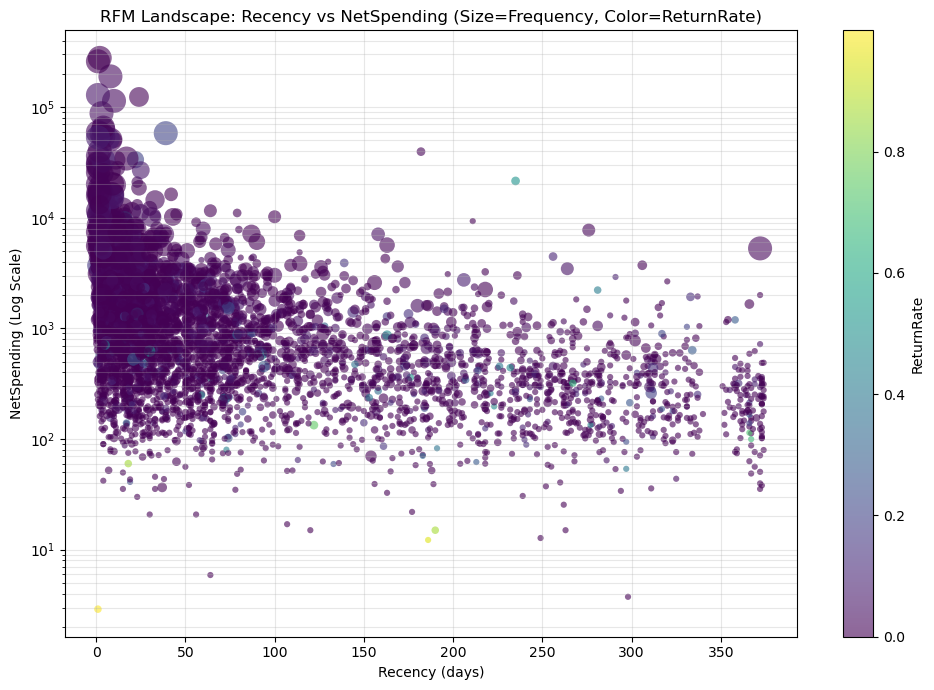

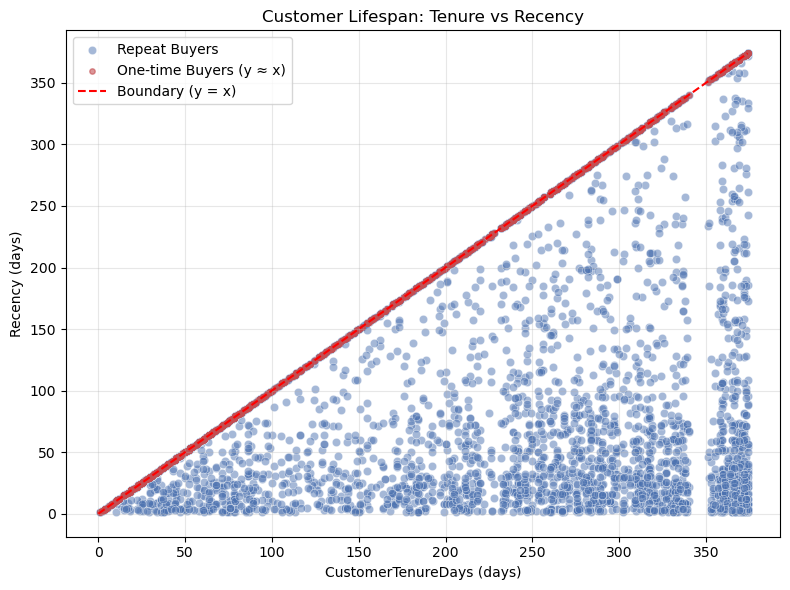

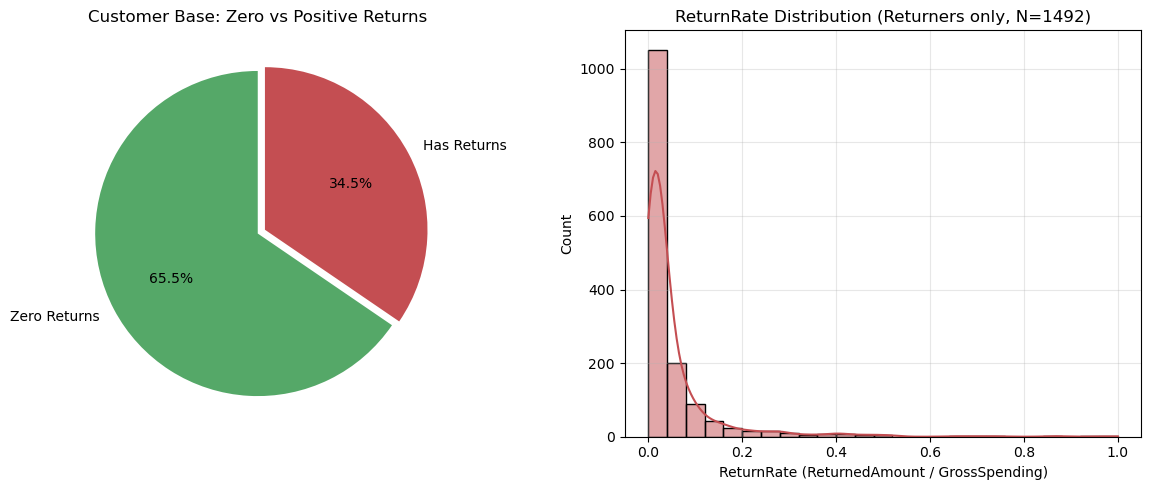

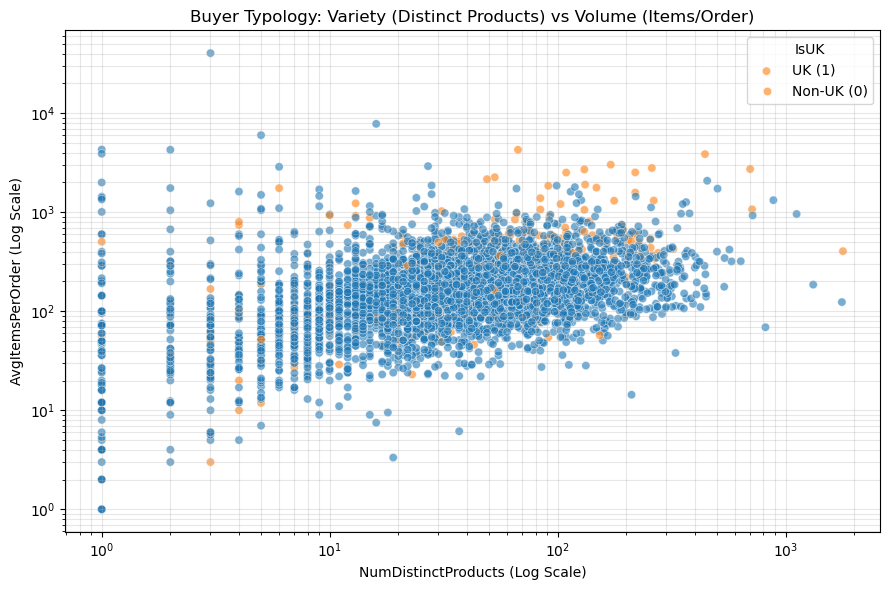

In [11]:
from src.visualization import (
    plot_feature_histograms,
    plot_feature_boxplots,
    plot_correlation_matrix,
    plot_pca_analysis,
    plot_log_transform_comparison,
    plot_pareto_revenue,
    plot_rfm_bubble_scatter,
    plot_tenure_vs_recency,
    plot_return_behavior_analysis,
    plot_wholesale_vs_retail,
)

# 1. Histograms (with UK split)
plot_feature_histograms(df, split_by_uk=True)

# 2. Boxplots (with UK split)
plot_feature_boxplots(df, split_by_uk=True)

# 3. Correlation heatmap
plot_correlation_matrix(df, method='spearman')
plot_correlation_matrix(df, method='pearson')

# 4. PCA scree plot, 2D projection, loadings
fig, axes, loadings = plot_pca_analysis(df)

# 5. Raw vs Log1p comparison
plot_log_transform_comparison(df)

# 6. Pareto 80/20 revenue curve
plot_pareto_revenue(df)

# 7. 4D RFM bubble landscape
plot_rfm_bubble_scatter(df)

# 8. Customer lifespan triangle (Tenure vs Recency)
plot_tenure_vs_recency(df)

# 9. Return behavior analysis
plot_return_behavior_analysis(df)

# 10. Buyer typology (Variety vs Volume)
plot_wholesale_vs_retail(df)

In [12]:
DEFAULT_NUMERIC_FEATURES = [
    'Recency',
    'Frequency',
    'NetSpending',
    'AvgOrderValue',
    'NumDistinctProducts',
    'CustomerTenureDays',
    'PurchaseVelocity_Monthly',
    'ReturnRate',
]

In [13]:
import numpy as np

In [14]:
for col in DEFAULT_NUMERIC_FEATURES:
    df[f"{col}_log1p"] = np.log1p(df[col].clip(lower=0))

In [15]:
columns = [col for col in df.columns if col.endswith("log1p")]

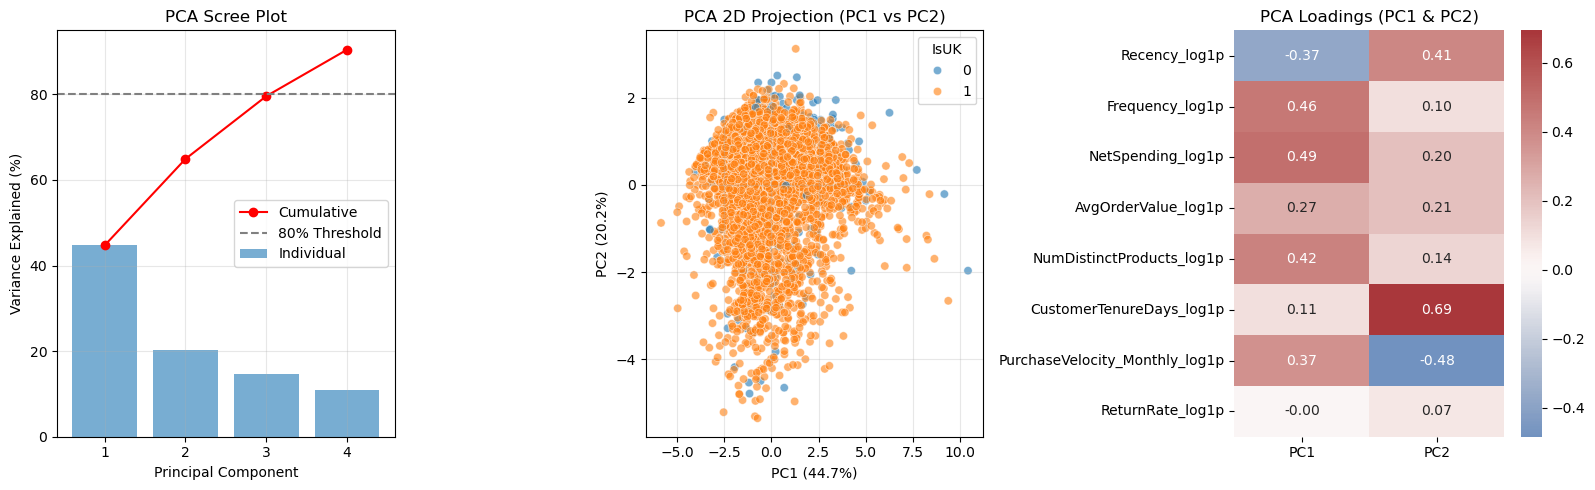

In [16]:
fig, axes, loadings = plot_pca_analysis(df=df, features=columns)

(<Figure size 1500x1200 with 9 Axes>,
 array([<Axes: title={'center': 'Boxplot: Recency_log1p'}, xlabel='IsUK', ylabel='Recency_log1p'>,
        <Axes: title={'center': 'Boxplot: Frequency_log1p'}, xlabel='IsUK', ylabel='Frequency_log1p'>,
        <Axes: title={'center': 'Boxplot: NetSpending_log1p'}, xlabel='IsUK', ylabel='NetSpending_log1p'>,
        <Axes: title={'center': 'Boxplot: AvgOrderValue_log1p'}, xlabel='IsUK', ylabel='AvgOrderValue_log1p'>,
        <Axes: title={'center': 'Boxplot: NumDistinctProducts_log1p'}, xlabel='IsUK', ylabel='NumDistinctProducts_log1p'>,
        <Axes: title={'center': 'Boxplot: CustomerTenureDays_log1p'}, xlabel='IsUK', ylabel='CustomerTenureDays_log1p'>,
        <Axes: title={'center': 'Boxplot: PurchaseVelocity_Monthly_log1p'}, xlabel='IsUK', ylabel='PurchaseVelocity_Monthly_log1p'>,
        <Axes: title={'center': 'Boxplot: ReturnRate_log1p'}, xlabel='IsUK', ylabel='ReturnRate_log1p'>,
        <Axes: >], dtype=object))

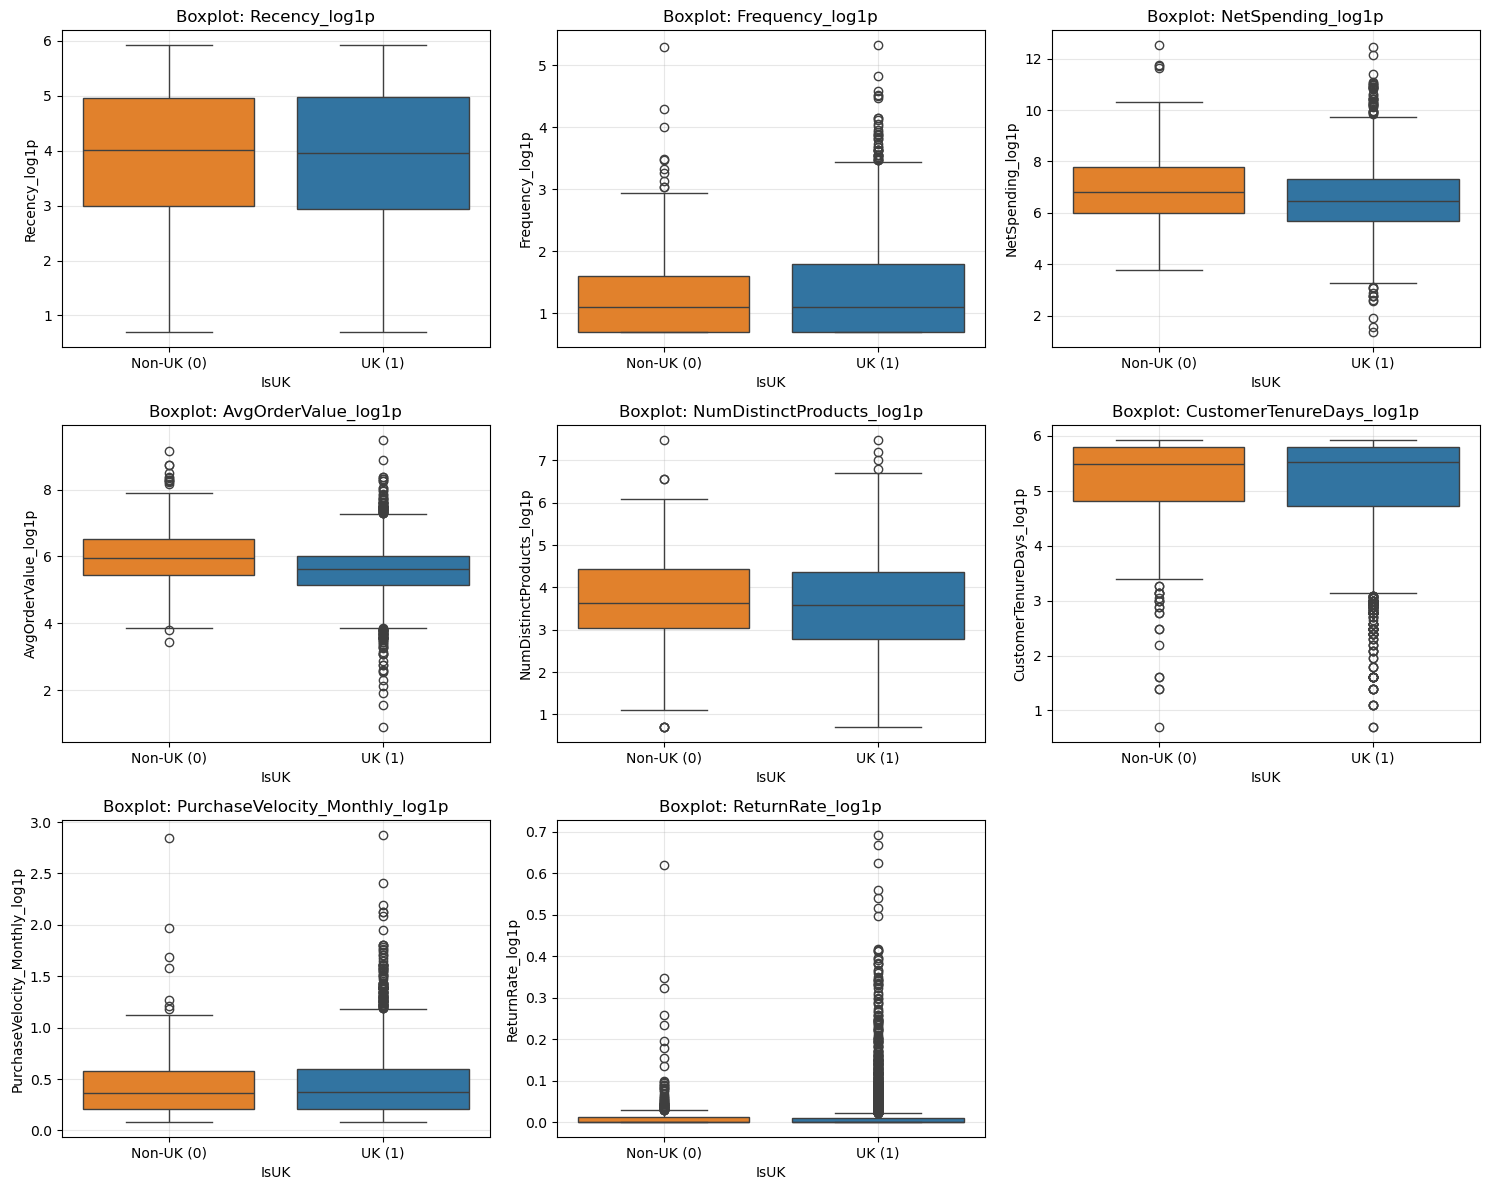

In [17]:
plot_feature_boxplots(df=df, features=columns, split_by_uk=True)

#### Comprehensive EDA Summary: Insights and Actions Across All 12 Visualizations

1. Feature Histograms (Split by UK vs. Non-UK)
- Insight: Almost all monetary, frequency, and basket-size features (`Frequency`, `NetSpending`, `GrossSpending`, `ReturnedAmount`, `CancelFrequency`, `NumDistinctProducts`, `AvgOrderValue`, `AvgItemsPerOrder`, and `PurchaseVelocity_Monthly`) exhibit severe right-skewness. Most customers are concentrated near the lower bound, while a small fraction of wholesale buyers forms an extreme right tail. `Recency` is moderately right-skewed due to high Q4 shopping activity, whereas `CustomerTenureDays` is bimodal, showing a large spike at `0` days (one-time buyers) and another near `350-373` days (long-term retained buyers). Domestic (`IsUK = 1`) and international (`IsUK = 0`) customers share similar distributional shapes, although international buyers shift slightly toward higher order values.
- Action: Apply `np.log1p` transformation to all right-skewed continuous features before standardization so that Euclidean distances in clustering are not distorted by extreme tail values.

2. Feature Boxplots (Split by UK vs. Non-UK)
- Insight: The interquartile ranges for raw spending and order frequency are tightly compressed near zero, accompanied by hundreds of extreme upper-tail points reaching up to 280,000 in `NetSpending` and over 200 orders in `Frequency`. International customers (`IsUK = 0`) show higher median `NetSpending`, `AvgOrderValue`, and `AvgItemsPerOrder`, reflecting bulk purchasing to offset cross-border shipping costs. However, the single largest wholesale outliers still reside within the UK market.
- Action: Do not cap or drop upper-tail outliers, as they represent genuine B2B and VIP accounts rather than data errors. Compress their scale via log transformation and retain `IsUK` as a post-clustering profiling variable rather than training separate geographic models.

3. Spearman Correlation Matrix
- Insight: Several feature pairs display near-perfect rank correlation, indicating severe multicollinearity:
  - `NetSpending` and `GrossSpending` (`r = 0.99`) capture virtually identical monetary scale.
  - `ReturnRate`, `ReturnedAmount`, and `CancelFrequency` (`r = 0.99 - 1.00`) are redundant representations of return behavior.
  - `AvgOrderValue` and `AvgItemsPerOrder` (`r = 0.82`) overlap heavily as basket-size indicators.
  - `Frequency` correlates positively with `CustomerTenureDays` (`r = 0.77`) and `NetSpending` (`r = 0.78`), while `Recency` correlates negatively with `Frequency` (`r = -0.59`) and `NetSpending` (`r = -0.52`).
- Action: Drop `GrossSpending`, `ReturnedAmount`, `CancelFrequency`, and `AvgItemsPerOrder` from the modeling feature set to prevent overweighting monetary volume, returns, and basket size during clustering.

4. PCA Analysis on Raw Features (12 Raw Features)
- Insight: On standardized raw features, PC1 (40.3%) and PC2 (15.4%) explain 55.7% of total variance, requiring 5 components to cross the 80% variance threshold. Due to unscaled extreme outliers, the 2D projection compresses the vast majority of customers into a dense blob near `(0, 0)` while stretching a few extreme wholesale accounts far along the axes (`PC1 > 40`, `PC2 > 25`).
- Action: Avoid running K-Means on raw standardized features, as the algorithm would waste clusters on isolated outlier points instead of partitioning the main customer population.

5. Raw vs. Log1p Transformation Comparison
- Insight: Applying `log1p` substantially normalizes heavy-tailed distributions and reduces skewness across all key metrics:
  - `NetSpending` skewness drops from `19.34` to `0.21`, forming a near-Gaussian bell curve.
  - `AvgOrderValue` skewness drops from `36.38` to `0.24`.
  - `NumDistinctProducts` skewness drops from `6.57` to `-0.08`.
  - `Frequency` (`12.10` to `1.20`), `PurchaseVelocity_Monthly` (`9.27` to `1.12`), and `ReturnRate` (`11.27` to `3.69`) also show major stability improvements.
- Action: Replace all raw continuous features with their `_log1p` counterparts prior to scaling and clustering.

6. Pareto Revenue Curve (80/20 Concentration)
- Insight: Revenue inequality is even more pronounced than the standard Pareto benchmark: the top `27.8%` of customers generate `80%` of total net revenue, while the remaining `72.2%` contribute only `20%`. Moreover, the top `5-10%` of accounts drive nearly half of overall sales.
- Action: Structure customer segmentation and downstream marketing budgets to prioritize high-touch retention for the top revenue-driving tiers, while utilizing low-cost automated campaigns for the long tail.

7. 4D RFM Bubble Landscape (Recency vs. NetSpending, Size = Frequency, Color = ReturnRate)
- Insight: A clear downward trajectory from top-left to bottom-right shows that active buyers (`Recency < 50` days) account for the highest `NetSpending` (`10,000 - 100,000+`) and highest order frequency. Once `Recency` exceeds `200` days, customers consist almost exclusively of low-frequency, low-monetary accounts (`< 500`). Elevated `ReturnRate` values appear across both one-time buyers and high-spending repeat buyers.
- Action: Establish automated re-engagement triggers for high-value customers entering the `60-150` day recency window before they decay into permanent churn (`> 200` days).

8. Customer Lifespan Triangle (CustomerTenureDays vs. Recency)
- Insight: Roughly one-third of all customers (`Frequency == 1`) lie directly on the upper diagonal boundary `y = x` (`Recency == CustomerTenureDays`), representing one-time buyers who never made a second purchase. Repeat buyers occupy the lower triangle (`Recency < Tenure`), clearly separating long-term active loyalists in the bottom-right corner (`Tenure > 300` days, `Recency < 30` days) from lapsed repeat buyers in the middle region (`Tenure > 150` days, `Recency > 100` days).
- Action: Retain both `CustomerTenureDays_log1p` and `Recency_log1p` so the clustering model can distinguish newly acquired customers, established loyalists, seasonal/lapsed repeat buyers, and churned one-time buyers.

#### 9. Return Behavior Analysis (Zero-Inflated Returns)
- Insight: Return behavior is highly zero-inflated: `63.6%` of customers never return any items (`ReturnRate == 0`), while `36.4%` (`1,575` customers) have recorded at least one return or cancellation. Among those who return, most maintain a low frictional return rate (`< 5%` of gross spend) typical of regular B2B ordering, whereas a small tail exhibits severe return rates (`30% - 100%`).
- Action: Use `ReturnRate_log1p` as the single relative return indicator so the model can isolate chronic high-rate returners without unfairly penalizing high-volume VIPs who have minor operational returns.

10. Buyer Typology: Variety (NumDistinctProducts) vs. Volume (AvgItemsPerOrder)
- Insight: The log-log scatter plot uncovers four behavioral purchasing profiles:
  - Small retail buyers (bottom-left): low SKU variety and small order quantities.
  - Specialized bulk wholesalers (top-left): narrow SKU variety but large unit quantities per order.
  - Assortment retailers / gift shops (bottom-right): broad catalog variety (`> 50` distinct SKUs) in moderate quantities.
  - Major distributors / VIPs (top-right): both broad catalog diversity and large order volumes.
- Action: Keep both `NumDistinctProducts_log1p` and `AvgOrderValue_log1p` in the feature matrix to differentiate assortment-focused buyers from volume-focused buyers.

11. PCA Analysis on All 12 Log1p Features
- Insight: Log transformation resolves the outlier compression seen in Plot 4, spreading customers evenly across the 2D plane and increasing 4-component cumulative variance to `~87%` (`PC1 = 44.7%`, `PC2 = 16.7%`). However, the loadings heatmap reveals that PC2 is heavily skewed by the three redundant return variables (`ReturnRate_log1p = 0.46`, `ReturnedAmount_log1p = 0.41`, `CancelFrequency_log1p = 0.35`), while `NetSpending_log1p` (`0.41`) and `GrossSpending_log1p` (`0.41`) double-count spending on PC1.
- Action: Remove the 4 collinear `_log1p` features (`GrossSpending_log1p`, `ReturnedAmount_log1p`, `CancelFrequency_log1p`, and `AvgItemsPerOrder_log1p`) to eliminate axis distortion.

12. PCA Analysis on the Refined 8 Log1p Features
- Insight: Pruning redundant features yields a balanced and interpretable latent space:
  - Variance explained: PC1 (`42.6%`) and PC2 (`22.6%`) together capture `65.2%` of total variance, reaching the `80%` threshold with just 3 components (`~90%` with 4 components).
  - PC1 (Customer Value and Engagement Scale): Loads positively on `NetSpending_log1p` (`0.51`), `Frequency_log1p` (`0.47`), `NumDistinctProducts_log1p` (`0.44`), `PurchaseVelocity_Monthly_log1p` (`0.30`), and `AvgOrderValue_log1p` (`0.29`), and negatively on `Recency_log1p` (`-0.38`).
  - PC2 (Lifecycle Tenure vs. Purchase Intensity): Loads positively on `CustomerTenureDays_log1p` (`0.68`) and `Recency_log1p` (`0.37`), and negatively on `PurchaseVelocity_Monthly_log1p` (`-0.56`), separating older hibernating/seasonal accounts (`PC2 > 0`) from high-velocity active/new buyers (`PC2 < 0`).
  - Independent return dimension: `ReturnRate_log1p` has near-zero weight on both PC1 (`-0.02`) and PC2 (`0.05`), demonstrating that return propensity is orthogonal to customer value and lifecycle stage (captured primarily in PC3).
- Action: Finalize the 8 log-transformed features (`Recency_log1p`, `Frequency_log1p`, `NetSpending_log1p`, `AvgOrderValue_log1p`, `NumDistinctProducts_log1p`, `CustomerTenureDays_log1p`, `PurchaseVelocity_Monthly_log1p`, `ReturnRate_log1p`), standardize them with `StandardScaler`, and proceed to clustering evaluation (Elbow method and Silhouette analysis).

In [18]:
df_final = df[[
    'Recency_log1p',
    'Frequency_log1p',
    'NetSpending_log1p',
    'AvgOrderValue_log1p',
    'NumDistinctProducts_log1p',
    'CustomerTenureDays_log1p',
    'PurchaseVelocity_Monthly_log1p',
    'ReturnRate_log1p'
]] 

In [20]:
df_final = df_final.reset_index()

In [35]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == "notebook":
    project_root = project_root.parent

# Make a new folder
cleaned_dir = project_root / "data" / "clustered"
cleaned_dir.mkdir(parents=True, exist_ok=True)

# Save file
output = cleaned_dir / "retail_online.parquet"
df_final.to_parquet(output, index=False)